In [28]:
from os.path import join, dirname
import os
import sys
import gc
import logging
import argparse
from copy import deepcopy
import numpy as np
import torchshow as ts
import torchvision
from einops import rearrange
from matplotlib import pyplot as plt

import torch
from torch import autocast
from torch.cuda.amp import GradScaler
import torch.nn.functional as F
import torch.distributed as dist
import torch.multiprocessing as mp

sys.path.append(join(dirname(dirname(os.getcwd()))))
sys.path.append(os.getcwd())

from memoryPerceiver.memory_perceiver.main.configuration import cf
from memoryPerceiver.memory_perceiver.core.model_wrapper import create_memories, reset_memories
from memoryPerceiver.memory_perceiver.core.distributed import setup_distributed, average_gradients, scatter_dummy_src, gather_dummy_src
from memoryPerceiver.memory_perceiver.core.miscellaneous import custom_random, print_cuda_tensors
import memoryPerceiver.memory_perceiver.isaac.trainer as tr
from memoryPerceiver.memory_perceiver.isaac.plot import Plotter
from memoryPerceiver.memory_perceiver.isaac.agent import ActorCritic, ActorCriticSimple, ActorCriticPerceiver, create_agent

from memoryPerceiver.memory_perceiver.core.model_net import PerceiverIO
from memoryPerceiver.memory_perceiver.core.model_wrapper import create_multimodal_perceiver, output_projection, input_embedding
from memoryPerceiver.memory_perceiver.core.rnn import SimpleRNN
from memoryPerceiver.memory_perceiver.core.uoro import UOROModel

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [39]:
device = 'cuda:0'
# model = create_agent(cf, device)
# memories = create_memories(model.actor, cf.num_envs, device=device)
# optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
# model.train()
# 1
model = UOROModel(2, 10, 1, 1e-3, device)

In [40]:
model.initialize_state(device)

In [41]:
x=torch.randn(1, 1, 2, device=device)
y=torch.ones(1, 1, device=device)
model.forward(x, y)

(0.13573643565177917,
 None,
 tensor([[[0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]]], device='cuda:0',
        requires_grad=True),
 tensor([[[ 0.2967, -0.0719,  0.0748, -0.0633,  0.2097,  0.1333,  0.0309,
           -0.2407, -0.3221, -0.3313]]], device='cuda:0',
        grad_fn=<CudnnRnnBackward0>))

In [42]:
loss_all=[]

In [50]:
l = []
loss_acc=0
for n in range(200000):
    for i in range(4):
        l.append(torch.randn(1, 1, 2, device=device))
    if len(l) > 1:
        x = l[-1]
        x_lagged = l.pop(0)
        y = x_lagged.mean(-1).detach()
        loss, _, _, _ = model.forward(x, y)
        loss_all.append(loss)
        loss_acc += loss
        if n%1000 == 0:
            print(loss_acc)
            loss_acc=0

0.09504532068967819
53.08903026535697
49.49332307661156
51.825183913370694
47.96405228742831
49.77778511731219
48.71646534691256
46.82693523871058
50.09581221026349
51.39179320226995
52.87555159185278
53.408563365982275
48.07115989415192
49.478124171542056
50.21577826466514
51.216341045177685
49.990880613609946
48.76704050201975
51.306617753842424
47.83361557284119
47.707195676561255
51.639929065672064


KeyboardInterrupt: 

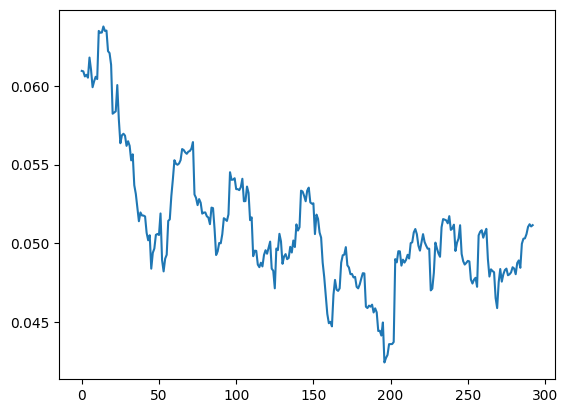

In [49]:
# plt.plot(loss_all)
h=100
plt.plot([sum(loss_all[i: i+h])/h for i in range(int(len(loss_all)/h))])
plt.show()

In [88]:
torch.tensor(loss_all)[:5000].mean()

tensor(4.0921)